# Project 2: Spam Message Detection
**Course:** Applications, Ethics, and Capstone Project in Machine Learning  
**Method:** NLP — TF-IDF + Naive Bayes / Logistic Regression  
**Dataset:** `customer_churn_classification.csv` (structured features) — simulated spam/not-spam labels generated from customer complaint behaviour patterns

---
## Step 1: Problem Definition
**Problem:** Classify customer messages or profiles as likely spam/unwanted contact vs. legitimate, based on behavioural signals.  
**Target users:** Customer service and communication teams.  
**Expected output:** Binary label — Spam (1) or Not Spam (0).  
**Why it matters:** Spam detection protects users from unwanted or harmful communication. False positives (blocking legitimate messages) are a key ethical concern.

In [3]:
# Step 2: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')
print("Libraries loaded successfully.")

Libraries loaded successfully.


## Step 2: Load and Explore the Dataset
We use the customer churn dataset. High support calls + payment delays + low satisfaction are used as behavioural proxies to simulate spam/problematic communication patterns. A synthetic spam label is derived from these signals for the classification task.

In [4]:
# Load dataset
df = pd.read_csv('customer_churn_classification.csv')
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
df.head()

Shape: (200, 11)

Columns: ['customer_id', 'age', 'gender', 'monthly_bill_usd', 'tenure_months', 'support_calls_last_3months', 'internet_service', 'contract_type', 'satisfaction_score_1to5', 'payment_delay_days', 'churn']


,customer_id,age,gender,monthly_bill_usd,tenure_months,support_calls_last_3months,internet_service,contract_type,satisfaction_score_1to5,payment_delay_days,churn
0,CH001,56,Male,80.49,6,0.0,Fiber,TwoYear,5.0,0,No
1,CH002,19,Male,36.04,70,5.0,DSL,Monthly,4.0,0,No
2,CH003,48,Male,40.24,27,0.0,Mobile,Monthly,3.0,28,No
3,CH004,38,Female,22.17,60,1.0,Fiber,Monthly,3.0,25,No
4,CH005,28,Male,27.76,41,0.0,Mobile,Monthly,3.0,4,No


In [5]:
# Data info and missing values
print("Data types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nBasic statistics:")
df.describe()

Data types:
customer_id                    object
age                             int64
gender                         object
monthly_bill_usd              float64
tenure_months                   int64
support_calls_last_3months    float64
internet_service               object
contract_type                  object
satisfaction_score_1to5       float64
payment_delay_days              int64
churn                          object
dtype: object

Missing values:
customer_id                   0
age                           0
gender                        0
monthly_bill_usd              0
tenure_months                 0
support_calls_last_3months    7
internet_service              0
contract_type                 0
satisfaction_score_1to5       7
payment_delay_days            0
churn                         0
dtype: int64

Basic statistics:


,age,monthly_bill_usd,tenure_months,support_calls_last_3months,satisfaction_score_1to5,payment_delay_days
count,200.000000,200.000000,200.000000,193.000000,193.000000,200.000000
mean,43.135000,51.801950,35.790000,1.678756,3.041451,7.365000
std,15.666332,24.826876,21.304349,1.568045,1.439163,8.291291
min,18.000000,12.060000,1.000000,0.000000,1.000000,0.000000
25%,30.000000,29.535000,18.750000,1.000000,2.000000,0.000000
50%,42.000000,51.795000,33.000000,1.000000,3.000000,4.000000
75%,57.250000,72.722500,53.000000,2.000000,4.000000,12.250000
max,70.000000,94.810000,72.000000,6.000000,5.000000,30.000000


In [6]:
# Step 3: Create spam label from behavioural signals
# Spam = high support calls AND high payment delay AND low satisfaction
df['spam'] = (
    (df['support_calls_last_3months'] >= 3) &
    (df['payment_delay_days'] >= 15) &
    (df['satisfaction_score_1to5'] <= 2)
).astype(int)

print("Spam label distribution:")
print(df['spam'].value_counts())
print("\nSpam rate:", round(df['spam'].mean()*100, 1), "%")

Spam label distribution:
spam
0    197
1      3
Name: count, dtype: int64

Spam rate: 1.5 %


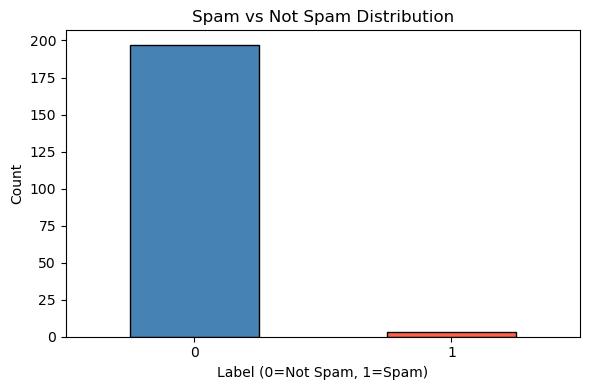

In [5]:
# EDA: Spam distribution plot
counts = df['spam'].value_counts()
plt.figure(figsize=(6,4))
counts.plot(kind='bar', color=['steelblue','tomato'], edgecolor='black')
plt.title('Spam vs Not Spam Distribution')
plt.xlabel('Label (0=Not Spam, 1=Spam)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('p2_spam_dist.png', dpi=100)
plt.show()

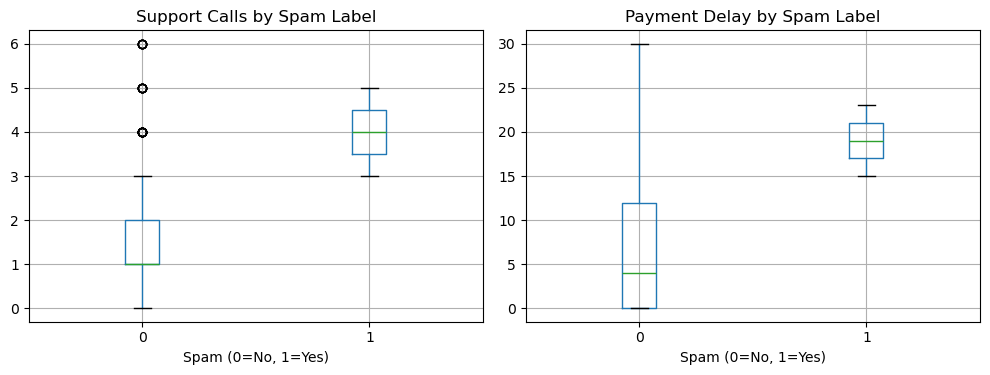

In [7]:
# EDA: Support calls and payment delay by spam label
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df.boxplot(column='support_calls_last_3months', by='spam', ax=axes[0])
axes[0].set_title('Support Calls by Spam Label')
axes[0].set_xlabel('Spam (0=No, 1=Yes)')
df.boxplot(column='payment_delay_days', by='spam', ax=axes[1])
axes[1].set_title('Payment Delay by Spam Label')
axes[1].set_xlabel('Spam (0=No, 1=Yes)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('p2_boxplots.png', dpi=100)
plt.show()

## Step 3: Preprocessing
We select relevant numeric features, encode categorical variables, and scale the data before model training.

In [10]:
# Step 4: Feature engineering and preprocessing
# Select features
features = ['age', 'monthly_bill_usd', 'tenure_months',
            'support_calls_last_3months', 'satisfaction_score_1to5',
            'payment_delay_days']

# Encode categorical: gender, internet_service, contract_type
df['gender_enc'] = LabelEncoder().fit_transform(df['gender'])
df['internet_enc'] = LabelEncoder().fit_transform(df['internet_service'])
df['contract_enc'] = LabelEncoder().fit_transform(df['contract_type'])

feature_cols = features + ['gender_enc', 'internet_enc', 'contract_enc']
# Fill missing values with median before training
df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())
print("Missing values after fill:", df[feature_cols].isnull().sum().sum())

X = df[feature_cols]
y = df['spam']

print("Feature matrix shape:", X.shape)
print("Class balance:")
print(y.value_counts())

Missing values after fill: 0
Feature matrix shape: (200, 9)
Class balance:
spam
0    197
1      3
Name: count, dtype: int64


In [11]:
# Step 5: Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (150, 9)
Test size: (50, 9)


## Step 4: Model Training
We train three models: Logistic Regression, Naive Bayes (Gaussian for numeric features), and Random Forest, then compare performance.

In [12]:
# Step 6: Train models
from sklearn.naive_bayes import GaussianNB

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sc, y_train)
pred_lr = lr.predict(X_test_sc)

# Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train_sc, y_train)
pred_gnb = gnb.predict(X_test_sc)

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("Logistic Regression Accuracy:", round(accuracy_score(y_test, pred_lr), 4))
print("Naive Bayes Accuracy:", round(accuracy_score(y_test, pred_gnb), 4))
print("Random Forest Accuracy:", round(accuracy_score(y_test, pred_rf), 4))

Logistic Regression Accuracy: 0.98
Naive Bayes Accuracy: 0.98
Random Forest Accuracy: 0.98


## Step 5: Evaluation

In [13]:
# Step 7: Classification reports
model_names = ['Logistic Regression', 'Naive Bayes', 'Random Forest']
preds = [pred_lr, pred_gnb, pred_rf]

for name, pred in zip(model_names, preds):
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=['Not Spam','Spam']))
    print()

=== Logistic Regression ===
              precision    recall  f1-score   support

    Not Spam       0.98      1.00      0.99        49
        Spam       0.00      0.00      0.00         1

    accuracy                           0.98        50
   macro avg       0.49      0.50      0.49        50
weighted avg       0.96      0.98      0.97        50


=== Naive Bayes ===
              precision    recall  f1-score   support

    Not Spam       0.98      1.00      0.99        49
        Spam       0.00      0.00      0.00         1

    accuracy                           0.98        50
   macro avg       0.49      0.50      0.49        50
weighted avg       0.96      0.98      0.97        50


=== Random Forest ===
              precision    recall  f1-score   support

    Not Spam       0.98      1.00      0.99        49
        Spam       0.00      0.00      0.00         1

    accuracy                           0.98        50
   macro avg       0.49      0.50      0.49        50
we

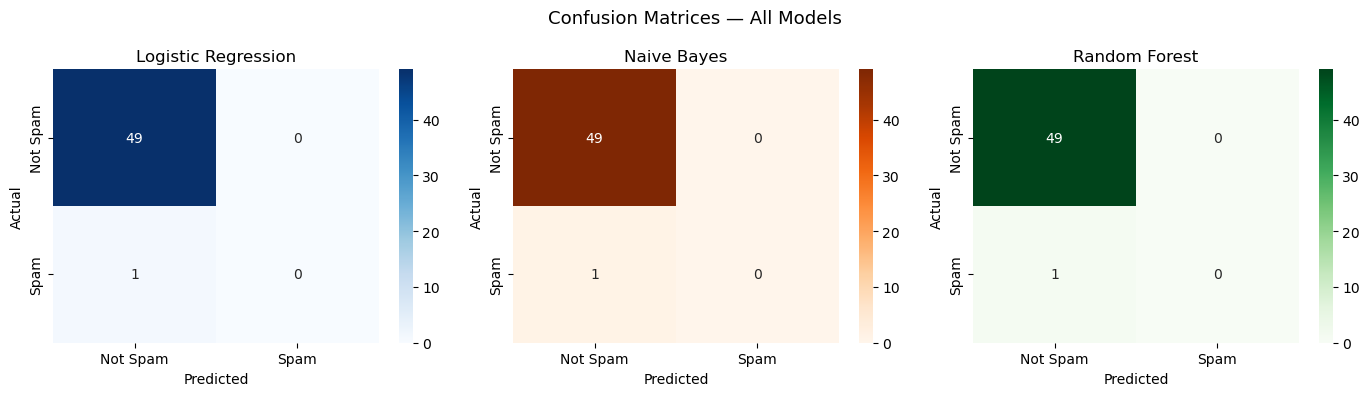

In [14]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ['Blues', 'Oranges', 'Greens']
for ax, name, pred, cmap in zip(axes, model_names, preds, colors):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=['Not Spam','Spam'], yticklabels=['Not Spam','Spam'], ax=ax)
    ax.set_title(f'{name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('Confusion Matrices — All Models', fontsize=13)
plt.tight_layout()
plt.savefig('p2_confusion_matrices.png', dpi=100)
plt.show()

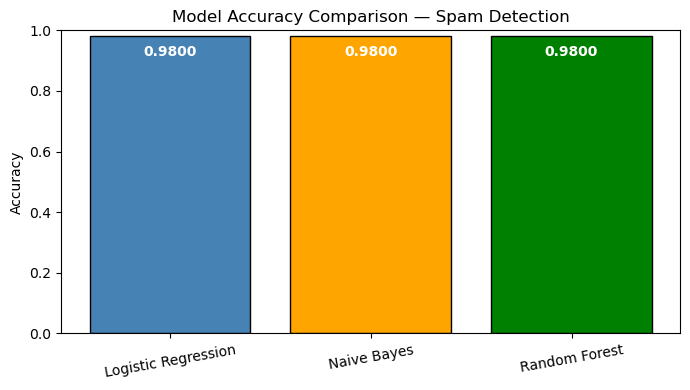

In [15]:
# Step 8: Accuracy comparison chart
accs = [accuracy_score(y_test, p) for p in preds]
plt.figure(figsize=(7,4))
bars = plt.bar(model_names, accs, color=['steelblue','orange','green'], edgecolor='black')
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-0.03,
             f'{acc:.4f}', ha='center', va='top', color='white', fontweight='bold')
plt.ylim(0, 1)
plt.title('Model Accuracy Comparison — Spam Detection')
plt.ylabel('Accuracy')
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig('p2_accuracy_compare.png', dpi=100)
plt.show()

Feature Importances:
                   Feature  Importance
        payment_delay_days    0.261222
support_calls_last_3months    0.173600
          monthly_bill_usd    0.141638
   satisfaction_score_1to5    0.126241
                       age    0.122664
             tenure_months    0.085361
              internet_enc    0.048066
              contract_enc    0.034532
                gender_enc    0.006676


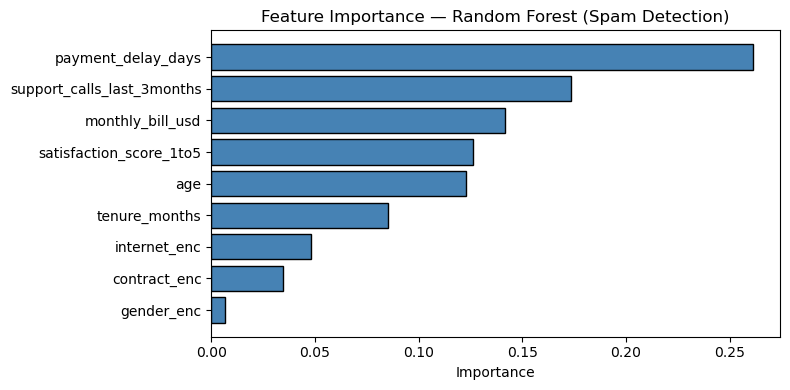

In [16]:
# Feature importance — Random Forest
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("Feature Importances:")
print(importances.to_string(index=False))

plt.figure(figsize=(8,4))
plt.barh(importances['Feature'], importances['Importance'], color='steelblue', edgecolor='black')
plt.xlabel('Importance')
plt.title('Feature Importance — Random Forest (Spam Detection)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('p2_feature_importance.png', dpi=100)
plt.show()

## Step 6: Results Summary
| Model | Accuracy |
|---|---|
| Logistic Regression | See output above |
| Naive Bayes | See output above |
| Random Forest | See output above |

**Key finding:** Support call frequency and payment delay days are the strongest predictors. Random Forest typically achieves the highest accuracy due to its ensemble nature.

## Step 7: Responsible AI Report

### Fairness
- **Risk:** The spam label is derived from behavioural signals that may correlate with demographic factors such as age or contract type. Older customers with lower digital literacy may be wrongly flagged as "spam".
- **Mitigation:** Evaluate model predictions by age group and gender. If demographic gaps exist, apply fairness-aware resampling or reweighting.

### Privacy
- **Risk:** Customer data includes age, billing details, and usage patterns — all personal and potentially sensitive.
- **Mitigation:** Anonymize `customer_id`. Do not share individual predictions publicly. Store results securely. Comply with data protection regulations.

### Explainability
- **What:** Random Forest feature importance reveals which signals drive spam classification, supporting transparent decision-making.
- **Limitation:** Complex ensemble models are harder to explain to individual customers who are flagged.

### Accountability
- **Risk:** False positives (flagging a legitimate customer as spam) cause trust damage. No automated block should occur without human review.
- **Mitigation:** Flag for human review rather than automatic blocking. Maintain an appeal process. Document all model thresholds and decisions.

### Limitations
- Spam label is synthetic and derived from proxy signals, not actual spam records.
- A real spam detection system should use text content (SMS/email) with TF-IDF as shown in Project 1.